# Visualization, etc. exercise

In this exercise, we will create a `matplotlib` figure with multiple axes, to plot some wire line log data from a gas reservoir. For a visual example of the type of plot we are trying to make, see figure 3 here: https://doi.org/10.1016/j.petrol.2018.11.023

![Wire line log data](exercise_files/wireline-log-example.jpg)


In [1]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt

First load the csv file (`exercise_files/wireline.csv`). You could use `pandas` to do this (and have the data in a DataFrame), or use `numpy` and store the data in an array (or multiple arrays)

In [2]:
# Let's use pandas here
df = pd.read_csv("exercise_files/wireline.csv", index_col=0)
df

,Facies,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE
0,3,2793.0,77.45,0.664,9.9,11.915,4.6
1,3,2793.5,78.26,0.661,14.2,12.565,4.1
2,3,2794.0,79.05,0.658,14.8,13.050,3.6
3,3,2794.5,86.10,0.655,13.9,13.115,3.5
4,3,2795.0,74.58,0.647,13.5,13.300,3.4
...,...,...,...,...,...,...,...
195,2,2890.5,83.69,0.684,12.4,11.310,4.0
196,2,2891.0,87.30,0.648,13.7,11.975,3.6
197,2,2891.5,89.07,0.619,13.7,12.065,3.6
198,2,2892.0,91.06,0.584,12.9,12.210,3.7


There are 5 numerical measurements at each depth (`GR`, `ILD_log10`, `DeltaPHI`, `PHIND`, `PE`). Don't worry what these mean, we just need to know we have 5 physical variables to plot. There is also a catagorical value for the rock type, `Facies`, and a column with the depth the measurements were taken.

So, we want to make a figures with 6 Axes instances (in 6 columns, 1 row). Using the `sharey=True` option to `plt.subplots()`, we can make sure all the Axes will share the same y-limits (and only need to set those for one Axes, rather than all of them individually).

In [3]:
fig, axes = plt.subplots(nrows=1, ncols=6, sharey=True)

We can set the y-limits to the minimum and maximum depth. We want the deeper values (i.e. higher depth values) to be lower on our figure, so y_min will be the maximum depth. Use the `ax.set_ylim` function to do this.

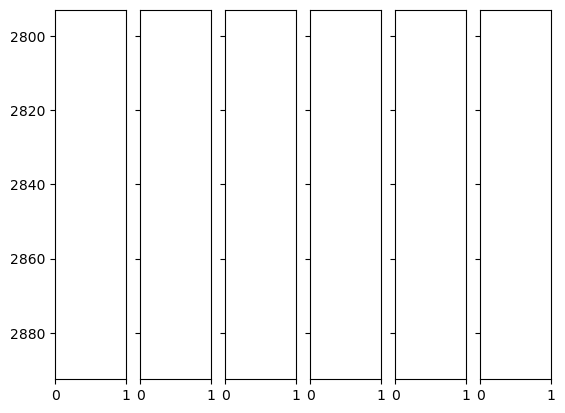

In [4]:
axes[0].set_ylim(df["Depth"].max(), df["Depth"].min())
fig

Now we can plot each variable on each of the first 5 Axes using `ax.plot`. Also set the ylabel for the first Axes.

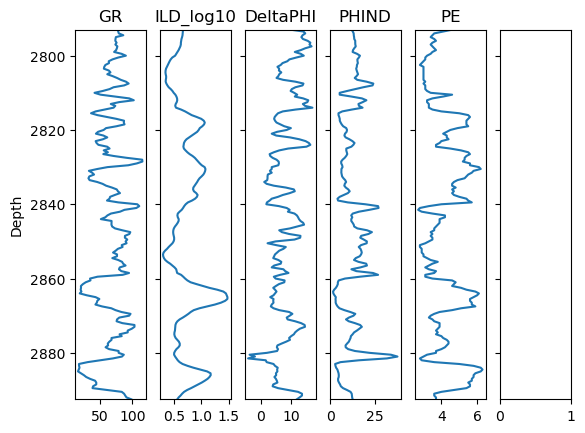

In [5]:
for ax, var in zip(fig.axes[:-1], ["GR", "ILD_log10", "DeltaPHI", "PHIND", "PE"]):
    ax.plot(df[var], df["Depth"])
    ax.set_title(var)

axes[0].set_ylabel("Depth")
fig

And finally, we can add the facies plot. Let's use the `pcolormesh` function for this. It might be useful to first create a 2D array, of shape (N, 2), from the facies array, to make plotting them on a pcolormesh possible. You could try using the `np.tile` function for this.

In [6]:
facies = np.tile(df["Facies"], (2, 1)).T
print(f"There are {len(np.unique(facies))} different facies")
print(np.unique(facies))
print(facies.shape)

There are 7 different facies
[2 3 4 5 6 7 8]
(200, 2)


We'll also want to create a new colormap with the correct number of colours. We can use `plt.get_cmap()` here, where we pass in the name of the colormap (try `"tab10"` to start with), and the number of unique colours needed -- can you find that from the facies array?

In [7]:
facies_cmap = plt.get_cmap("tab10", len(np.unique(facies)))

Now we can create the pcolormesh. Some hints:

- Don't forget to use the cmap you created above. 
- You can also set the `vmin` and `vmax` to pin the top and bottom values of the colorbar. To get the facies labels in the middle of each color, try adding 0.5 to the top, and taking 0.5 away from the bottom value.
- Since we have the same number of depth values as we have facies, we will want to set `shading="nearest"`
- You'll also need to give some values for the X coordinates. Using [0, 1] here should work, but you'll want to turn off the meaningless x-ticks.

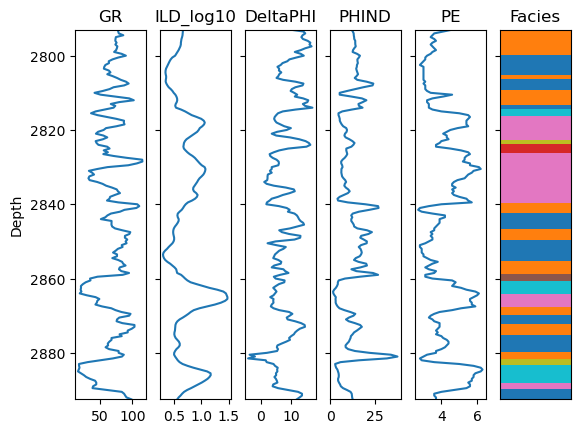

In [8]:
p = axes[-1].pcolormesh([0, 1], df["Depth"], facies,
                        shading="nearest", cmap=facies_cmap, vmin=1.5, vmax=8.5)
axes[-1].set_title("Facies")

# Turn off meaningless tick labels
axes[-1].set_xticks([])
fig

If you saved the output from pcolormesh above with a variable name, you can use that to create a colorbar now.

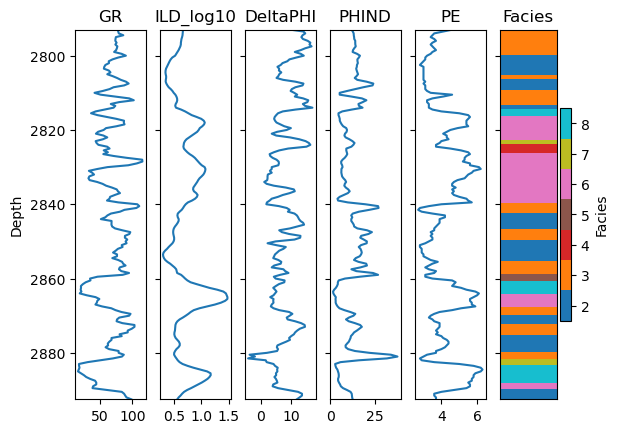

In [9]:
fig.colorbar(p, label="Facies")
fig